In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = pd.read_csv("dataset_1.csv", parse_dates=["date"])

In [3]:
data.head(20)

,match_id,date,team_a,team_b,goals_a,goals_b,team_a_goals_for_5,team_a_goals_against_5,team_b_goals_for_5,team_b_goals_against_5,prior_goal_difference_difference,rest_difference,host_advantage,knockout,goal_difference
0,1,11/06/2026,Mexico,South Africa,2,0,0.0,0.0,0.0,0.0,0,0,1,0,2
1,2,11/06/2026,South Korea,Czechia,2,1,0.0,0.0,0.0,0.0,0,0,0,0,1
2,3,12/06/2026,Canada,Bosnia and Herzegovina,1,1,0.0,0.0,0.0,0.0,0,0,1,0,0
3,4,12/06/2026,USA,Paraguay,4,1,0.0,0.0,0.0,0.0,0,0,1,0,3
4,5,13/06/2026,Qatar,Switzerland,1,1,0.0,0.0,0.0,0.0,0,0,0,0,0
5,6,13/06/2026,Brazil,Morocco,1,1,0.0,0.0,0.0,0.0,0,0,0,0,0
6,7,13/06/2026,Haiti,Scotland,0,1,0.0,0.0,0.0,0.0,0,0,0,0,-1
7,8,13/06/2026,Australia,Turkey,2,0,0.0,0.0,0.0,0.0,0,0,0,0,2
8,9,14/06/2026,Germany,Curacao,7,1,0.0,0.0,0.0,0.0,0,0,0,0,6
9,10,14/06/2026,Netherlands,Japan,2,2,0.0,0.0,0.0,0.0,0,0,0,0,0


In [4]:
print(data.isna().sum())

match_id                            0
date                                0
team_a                              0
team_b                              0
goals_a                             0
goals_b                             0
team_a_goals_for_5                  0
team_a_goals_against_5              0
team_b_goals_for_5                  0
team_b_goals_against_5              0
prior_goal_difference_difference    0
rest_difference                     0
host_advantage                      0
knockout                            0
goal_difference                     0
dtype: int64


In [5]:
print(data.map(lambda value: isinstance(value, str)).any())

match_id                            False
date                                 True
team_a                               True
team_b                               True
goals_a                             False
goals_b                             False
team_a_goals_for_5                  False
team_a_goals_against_5              False
team_b_goals_for_5                  False
team_b_goals_against_5              False
prior_goal_difference_difference    False
rest_difference                     False
host_advantage                      False
knockout                            False
goal_difference                     False
dtype: bool


In [6]:
parsed_dates = pd.to_datetime(
    data["date"], format="%Y-%m-%d", errors="coerce")
print(data.loc[data["date"].notna() & parsed_dates.isna(), "date"])

0      11/06/2026
1      11/06/2026
2      12/06/2026
3      12/06/2026
4      13/06/2026
          ...    
99     12/07/2026
100    14/07/2026
101    15/07/2026
102    18/07/2026
103    19/07/2026
Name: date, Length: 104, dtype: str


In [7]:
data["date"] = pd.to_datetime(data["date"], format="%d/%m/%Y")
print(data["date"].dtype)
print(data["date"].head())

datetime64[us]
0   2026-06-11
1   2026-06-11
2   2026-06-12
3   2026-06-12
4   2026-06-13
Name: date, dtype: datetime64[us]


In [8]:
print(data.map(lambda value: isinstance(value, str)).any())

match_id                            False
date                                False
team_a                               True
team_b                               True
goals_a                             False
goals_b                             False
team_a_goals_for_5                  False
team_a_goals_against_5              False
team_b_goals_for_5                  False
team_b_goals_against_5              False
prior_goal_difference_difference    False
rest_difference                     False
host_advantage                      False
knockout                            False
goal_difference                     False
dtype: bool


In [9]:
features = [
    "team_a_goals_for_5", "team_a_goals_against_5",
    "team_b_goals_for_5", "team_b_goals_against_5",
    "prior_goal_difference_difference", "rest_difference",
    "host_advantage", "knockout",
]


print("Rows:", len(data))
print("Unique matches:", data["match_id"].nunique())
print("Number of predictors:", len(features))
print(data[features + ["goal_difference"]].isna().sum())

Rows: 104
Unique matches: 104
Number of predictors: 8
team_a_goals_for_5                  0
team_a_goals_against_5              0
team_b_goals_for_5                  0
team_b_goals_against_5              0
prior_goal_difference_difference    0
rest_difference                     0
host_advantage                      0
knockout                            0
goal_difference                     0
dtype: int64


In [10]:
sns.set_theme(style="whitegrid")

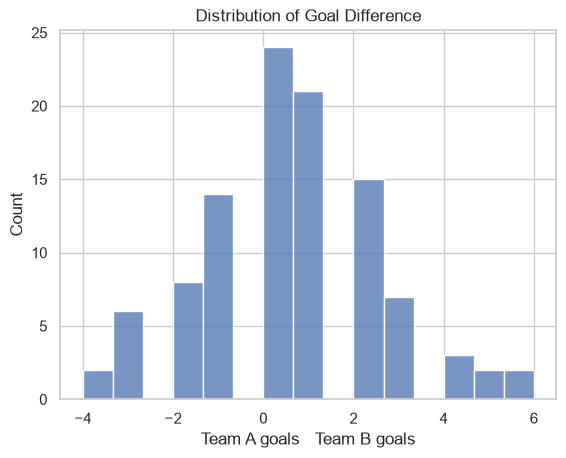

In [11]:
sns.histplot(data=data, x="goal_difference", bins=15)
plt.title("Distribution of Goal Difference")
plt.xlabel("Team A goals   Team B goals")
plt.show()

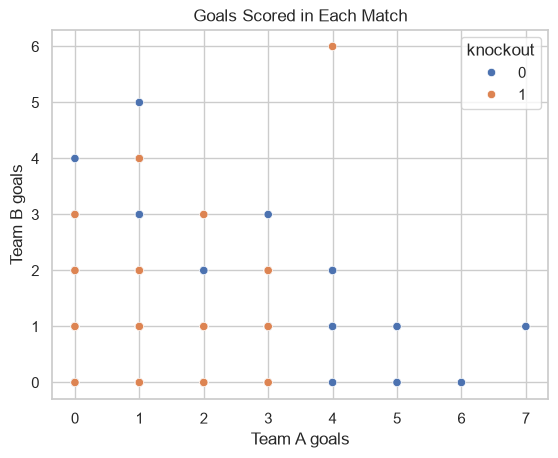

In [12]:
sns.scatterplot(data=data, x="goals_a", y="goals_b", hue="knockout")
plt.title("Goals Scored in Each Match")
plt.xlabel("Team A goals")
plt.ylabel("Team B goals")
plt.show()

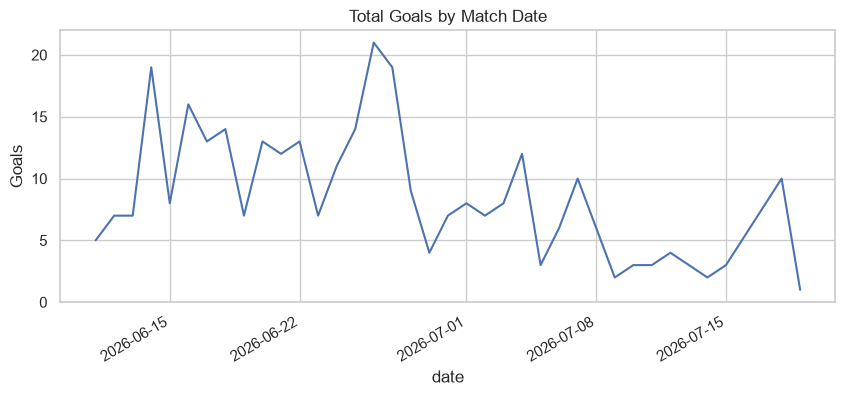

In [13]:
daily_goals = data.assign(
    total_goals=data["goals_a"] + data["goals_b"]
).groupby("date")["total_goals"].sum()

daily_goals.plot(figsize=(10, 4))
plt.title("Total Goals by Match Date")
plt.ylabel("Goals")
plt.show()

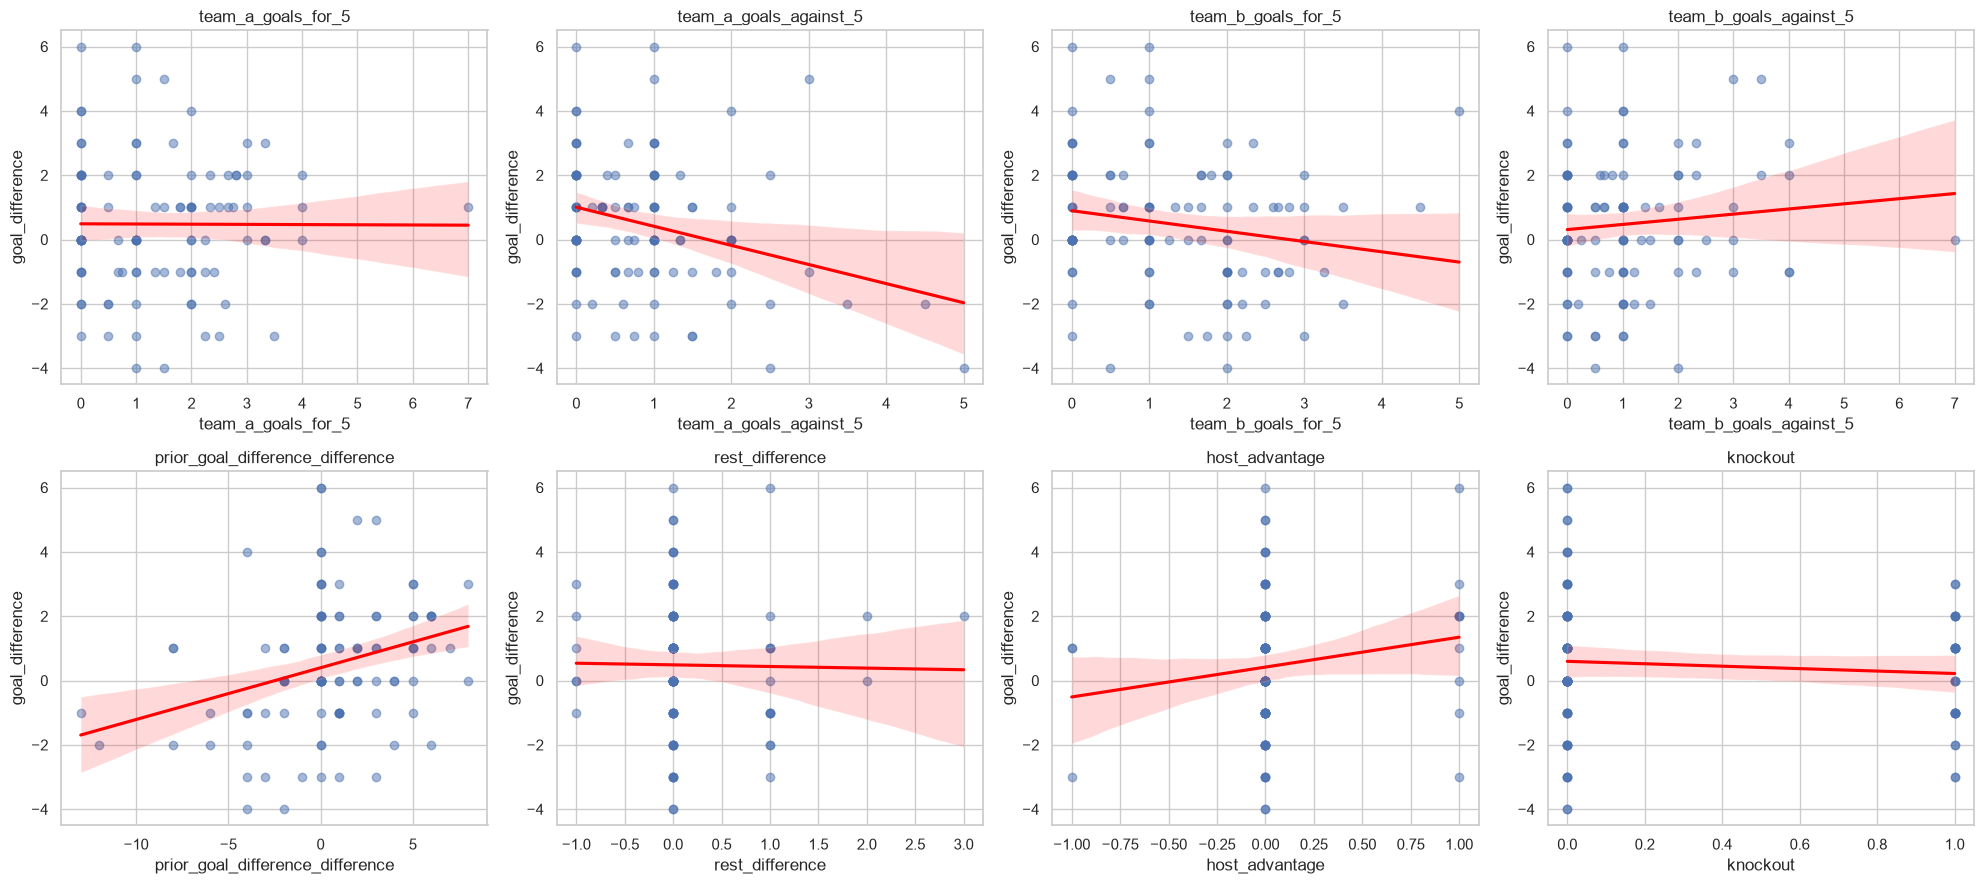

In [14]:
features = [
    "team_a_goals_for_5", "team_a_goals_against_5",
    "team_b_goals_for_5", "team_b_goals_against_5",
    "prior_goal_difference_difference", "rest_difference",
    "host_advantage", "knockout",
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for ax, feature in zip(axes.flat, features):
    sns.regplot(
        data=data, x=feature, y="goal_difference", ax=ax,
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )
    ax.set_title(feature)

plt.tight_layout()
plt.show()

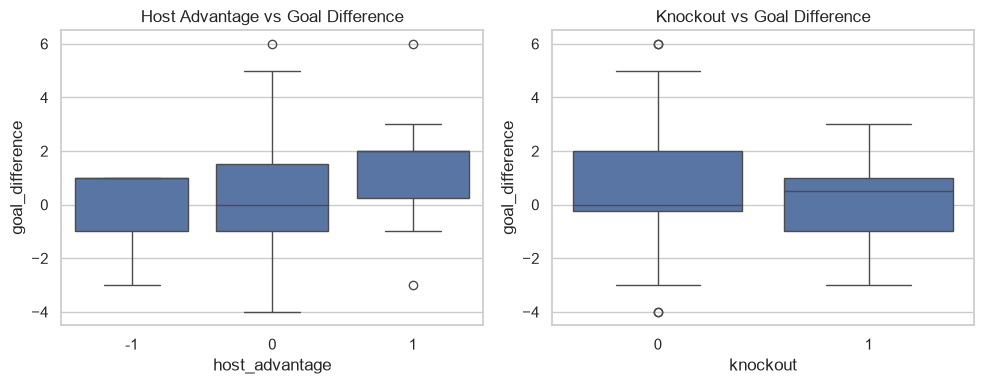

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(data=data, x="host_advantage",
            y="goal_difference", ax=axes[0])
axes[0].set_title("Host Advantage vs Goal Difference")

sns.boxplot(data=data, x="knockout",
            y="goal_difference", ax=axes[1])
axes[1].set_title("Knockout vs Goal Difference")

plt.tight_layout()
plt.show()

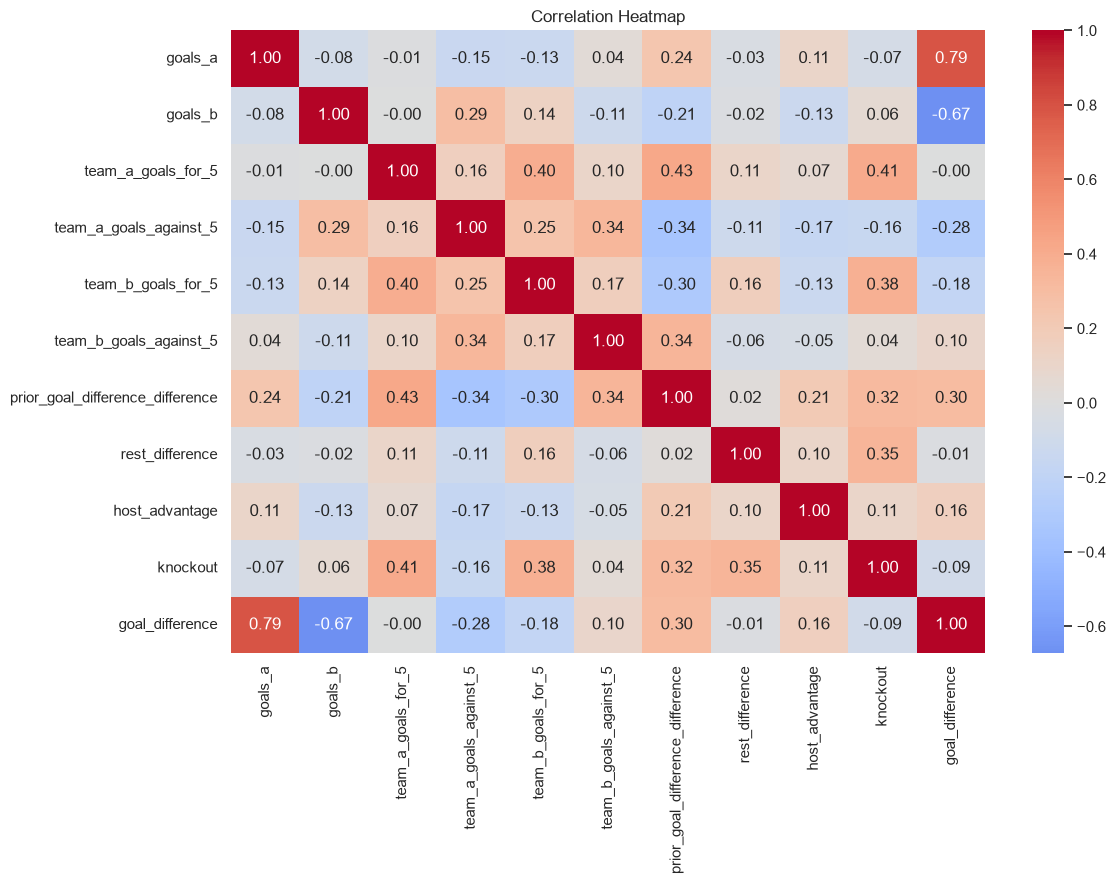

In [16]:
numeric_data = data.select_dtypes(include="number")
correlations = numeric_data.drop(columns=["match_id"], errors="ignore").corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlations, annot=True, cmap="coolwarm",
            center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
ordered = data.sort_values(["date", "match_id"]).reset_index(drop=True)
split = int(len(ordered) * 0.8)

train = ordered.iloc[:split]
test = ordered.iloc[split:]

X_train, X_test = train[features], test[features]
y_train, y_test = train["goal_difference"], test["goal_difference"]

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R²:", r2_score(y_test, predictions))
print(f"Baseline MAE: {mean_absolute_error(y_test, baseline):.3f}")

print(pd.Series(model.coef_, index=features, name="coefficient"))

MAE: 1.4606617716175978
RMSE: 2.094668241186997
R²: -0.8713221014710884
Baseline MAE: 1.426
team_a_goals_for_5                 -0.283274
team_a_goals_against_5             -0.303051
team_b_goals_for_5                  0.450313
team_b_goals_against_5             -0.091458
prior_goal_difference_difference    0.308854
rest_difference                     0.390542
host_advantage                      0.851422
knockout                           -0.893361
Name: coefficient, dtype: float64


In [18]:
results = test[["date", "team_a", "team_b"]].copy()
results["actual_goal_difference"] = y_test
results["predicted_goal_difference"] = predictions
results["error"] = results["actual_goal_difference"] - results["predicted_goal_difference"]

print(results.to_string(index=False))

      date      team_a      team_b  actual_goal_difference  predicted_goal_difference     error
2026-07-03    Portugal     Croatia                       1                   1.451145 -0.451145
2026-07-03 Switzerland     Algeria                       2                   2.574199 -0.574199
2026-07-04   Australia       Egypt                       0                   0.407879 -0.407879
2026-07-04   Argentina  Cabo Verde                       1                   1.521139 -0.521139
2026-07-04    Colombia       Ghana                       1                   0.663442  0.336558
2026-07-04    Paraguay      France                      -1                  -2.821713  1.821713
2026-07-04      Canada     Morocco                      -3                   1.125366 -4.125366
2026-07-05      Brazil      Norway                      -1                   2.065113 -3.065113
2026-07-06      Mexico     England                      -1                   2.019795 -3.019795
2026-07-06    Portugal       Spain      